# Лабораторная работа №3. Оптимизация гиперпараметров

Используем Wine Quality из первой работы. Предсказываем оценку вина по физико-химическим характеристикам и типу вина. Сравниваем исходный градиентный бустинг с конфигурациями, найденными Grid Search и Random Search.

Основная метрика — RMSE в баллах оценки вина. Чем она меньше, тем лучше. Квадрат ошибки сильнее штрафует большие отклонения. CV RMSE считаем как среднее пяти RMSE, по одному на каждый валидационный фолд.

Источник данных — [Wine Quality, UCI, CC BY 4.0](https://doi.org/10.24432/C56S3T).

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import (
    GridSearchCV, GroupKFold, GroupShuffleSplit, ParameterGrid,
    RandomizedSearchCV, cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
N_FOLDS = 5
N_JOBS = 6
SCORING = "neg_root_mean_squared_error"
DATA_DIR = Path("data")

## 1. Данные и разбиение

Воспроизводим подготовку данных из первой лабы. Объединяем красное и белое вино, добавляем тип и удаляем полные дубликаты. Строки с одинаковыми входными признаками держим в одной группе, даже если их оценки различаются. Одни и те же группы не могут оказаться по разные стороны разбиения.

Оставляем около 20% для финальной оценки. Это тот же локальный test, который уже использовался в лабе №1. Его результаты интерпретируем как повторную оценку на знакомом разбиении.

На train используем пять групповых фолдов. В каждом около 80% обучающих данных идёт на подгонку и 20% на валидацию. Пять оценок дают представление о среднем качестве и разбросе при умеренной стоимости вычислений. Одно разбиение может случайно оказаться лёгким или сложным. Если многократно выбирать параметры по test, модель подбора приспособится к особенностям этой выборки, и итоговая оценка станет оптимистичной.

In [2]:
# Читаем данные, удаляем полные дубликаты и определяем группы.
red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
wine = pd.concat(
    [red.assign(wine_type="red"), white.assign(wine_type="white")],
    ignore_index=True,
).drop_duplicates().reset_index(drop=True)

X = wine.drop(columns="quality")
y = wine["quality"]
groups = wine.groupby(list(X.columns), sort=False, dropna=False).ngroup()

Выделяем test с фиксированным seed. Группы одинаковых входных признаков целиком относятся к одной части данных.

In [3]:
# Воспроизводим отложенную выборку первой лабы.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
groups_train = groups.iloc[train_idx].to_numpy()
print(f"Уникальных строк: {len(wine)}. Train: {len(train_idx)}. Test: {len(test_idx)}.")

Уникальных строк: 5320. Train: 4256. Test: 1064.


На оставшейся обучающей части заранее формируем общие пять CV-фолдов для всех моделей.

In [4]:
# Проверяем отсутствие общих групп между частями каждого фолда.
cv = list(GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
          .split(X_train, y_train, groups_train))
for fit_idx, valid_idx in cv:
    assert set(groups_train[fit_idx]).isdisjoint(groups_train[valid_idx])

print("Размеры валидационных фолдов:", [len(valid) for _, valid in cv])

Размеры валидационных фолдов: [852, 851, 851, 851, 851]


## 2. Исходная модель и пространство поиска

Baseline этой работы — бустинг с настройками из лабы №1. Медиану для заполнения пропусков и кодирование типа вина включаем в Pipeline, чтобы обработка обучалась внутри каждого фолда. Для всех конфигураций фиксируем min_samples_leaf=5.

| Параметр | Что меняет | Grid Search | Random Search | Ожидаемый эффект |
|---|---|---|---|---|
| n_estimators | Число деревьев | 60, 200, 400 | Целые от 60 до 400 | При малом числе деревьев модель может недоучиться, при большом растут время и риск переобучения |
| learning_rate | Вклад каждого нового дерева | 0.02, 0.05, 0.15 | От 0.02 до 0.15, равномерно в логарифмической шкале | Малый шаг обычно требует больше деревьев, большой быстрее снижает ошибку на train |
| max_depth | Максимальная глубина дерева | 1, 3, 6 | Целые от 1 до 6 | Глубокие деревья учитывают более сложные взаимодействия, но сильнее подгоняются под train |

Границы включают исходные настройки и позволяют сравнить простые и более гибкие модели. Grid Search проверяет 27 комбинаций. Random Search проверяет тоже 27 комбинаций, выбирая значения из указанных диапазонов. Это по 135 обучений на фолдах для каждого поиска. Фиксируем зерно случайного поиска и используем одинаковые фолды и число рабочих потоков.

### Почему выбраны эти диапазоны

У исходной модели 400 деревьев, шаг 0.05 и глубина 3. Для каждого параметра включаем исходное значение в сетку и проверяем значения по обе стороны от него там, где это позволяет выбранный вычислительный бюджет.

Число деревьев n_estimators проверяем на 60, 200 и 400. На 60 итерациях можно увидеть, хватает ли модели шагов для обучения. Значение 200 позволяет проверить, можно ли получить сопоставимое качество с меньшими затратами. Значение 400 соответствует исходной модели. Верхнюю границу фиксируем заранее, чтобы ограничить стоимость каждого запуска.

Для learning_rate берём 0.02, 0.05 и 0.15. Шаг 0.02 даёт медленное накопление поправок, 0.05 воспроизводит исходный шаг, а 0.15 позволяет проверить более быстрое обучение. Этот параметр рассматриваем вместе с числом деревьев. При малом шаге 60 деревьев может оказаться недостаточно, а при большом шаге 400 итераций могут привести к подгонке под обучающие данные. В случайном поиске логарифмическое распределение выделяет одинаковую вероятность одинаковым относительным изменениям шага.

Для max_depth берём 1, 3 и 6. Дерево глубины 1 делает одно разбиение и даёт простую поправку к прогнозу. Глубина 3 соответствует исходной модели. Глубина 6 позволяет учитывать более сложные взаимодействия признаков и проверить, окупается ли дополнительная гибкость на валидации. В случайном поиске доступны также промежуточные глубины 2, 4 и 5.

min_samples_leaf=5 фиксируем как в исходном бустинге. Это сохраняет минимальное число наблюдений в листе и позволяет связать изменения качества с тремя исследуемыми параметрами. Диапазоны заданы до просмотра итоговых Test RMSE.

In [5]:
# Обработка признаков обучается внутри Pipeline.
preprocessing = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), list(X.select_dtypes("number").columns)),
    ("type", OneHotEncoder(categories=[["red", "white"]], drop="first",
                           handle_unknown="ignore", sparse_output=False), ["wine_type"]),
])
pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("model", GradientBoostingRegressor(min_samples_leaf=5, random_state=SEED)),
])

Фиксируем настройки исходного бустинга и оцениваем его на тех же фолдах, которые используем для обоих поисков.

In [6]:
# Получаем исходное качество для дальнейшего сравнения.
baseline = clone(pipeline).set_params(
    model__n_estimators=400, model__learning_rate=0.05, model__max_depth=3,
)
with parallel_config(backend="threading"):
    baseline_cv = cross_validate(baseline, X_train, y_train, cv=cv, scoring=SCORING,
                                 return_train_score=True, n_jobs=N_JOBS, error_score="raise")
print(f"Исходная модель: CV RMSE = {-baseline_cv['test_score'].mean():.4f}")

Исходная модель: CV RMSE = 0.7031


## 3. Grid Search и Random Search

Время измеряем от запуска поиска до получения CV-результатов. Модели с выбранными параметрами обучим на всём train после сравнения. Скорер sklearn возвращает RMSE со знаком минус, чтобы больший score соответствовал лучшей модели. В таблицах и на графиках возвращаем обычную положительную RMSE.

In [7]:
# Задаём сетку, распределения и одинаковое число попыток.
grid = {
    "model__n_estimators": [60, 200, 400],
    "model__learning_rate": [0.02, 0.05, 0.15],
    "model__max_depth": [1, 3, 6],
}
distributions = {
    "model__n_estimators": randint(60, 401),
    "model__learning_rate": loguniform(0.02, 0.15),
    "model__max_depth": randint(1, 7),
}
budget = len(ParameterGrid(grid))
options = dict(cv=cv, scoring=SCORING, return_train_score=True, refit=False,
               n_jobs=N_JOBS, error_score="raise")
searches = {
    "Grid Search": GridSearchCV(pipeline, grid, **options),
    "Random Search": RandomizedSearchCV(
        pipeline, distributions, n_iter=budget, random_state=SEED, **options),
}

Запускаем поиски последовательно. Для каждого используем одинаковое число рабочих потоков и измеряем фактическое время выполнения.

In [8]:
# Каждый поиск оценивает конфигурации только на train.
search_rows = {}
for name, search in searches.items():
    started = perf_counter()
    with parallel_config(backend="threading"):
        search.fit(X_train, y_train)
    elapsed = perf_counter() - started
    search_rows[name] = {
        **{key.removeprefix("model__"): value for key, value in search.best_params_.items()},
        "Комбинаций": len(search.cv_results_["params"]),
        "CV RMSE": -search.best_score_,
        "Время, с": elapsed,
    }

Сравниваем лучшие CV-результаты и затраты времени при одинаковом числе проверенных комбинаций.

In [9]:
# Собираем параметры победителей и результаты поиска.
search_summary = pd.DataFrame.from_dict(search_rows, orient="index")
assert search_summary["Комбинаций"].eq(budget).all()
display(search_summary.round(4))

,learning_rate,max_depth,n_estimators,Комбинаций,CV RMSE,"Время, с"
Grid Search,0.0500,6,200,27,0.7023,53.6315
Random Search,0.0471,6,165,27,0.7012,67.3896


## 4. Влияние гиперпараметров

Для каждого параметра берём срез сетки через лучшую конфигурацию Grid Search. Два других параметра фиксируем на её значениях. Полоса показывает одно стандартное отклонение валидационной RMSE по фолдам. На тепловой карте фиксируем глубину и смотрим, как шаг обучения взаимодействует с числом деревьев.

In [10]:
# Приводим результаты сетки к таблице для построения графиков.
grid_results = pd.DataFrame(searches["Grid Search"].cv_results_)
param_columns = {f"param_{name}": name.removeprefix("model__") for name in grid}
grid_results = grid_results.rename(columns=param_columns)
grid_results["CV RMSE"] = -grid_results["mean_test_score"]
grid_results["Train RMSE"] = -grid_results["mean_train_score"]
grid_best = searches["Grid Search"].best_params_

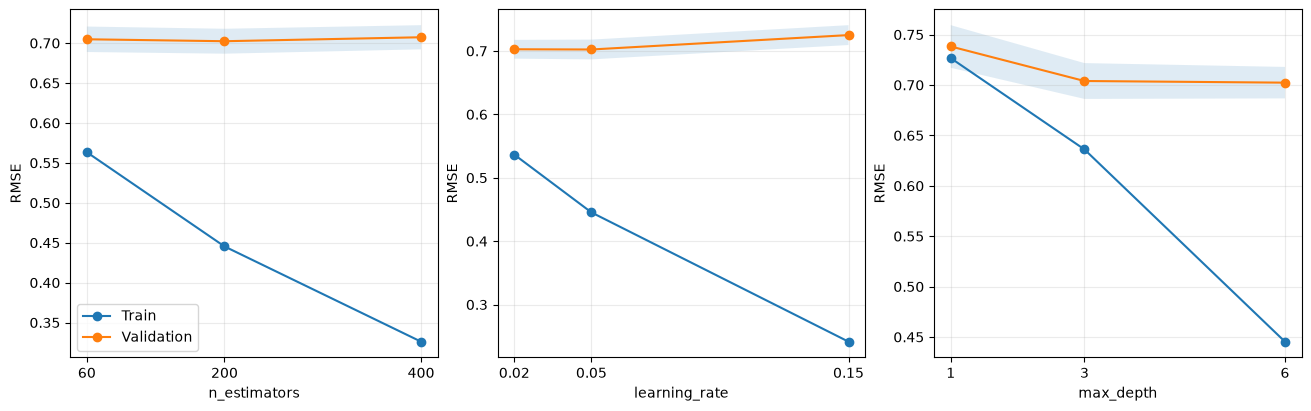

In [11]:
# Меняем один параметр, фиксируя два остальных.
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, param in zip(axes, grid):
    mask = np.ones(len(grid_results), dtype=bool)
    for fixed, value in grid_best.items():
        if fixed != param:
            mask &= grid_results[fixed.removeprefix("model__")].eq(value).to_numpy()
    name = param.removeprefix("model__")
    profile = grid_results.loc[mask].sort_values(name)
    x = profile[name].to_numpy(dtype=float)
    valid = profile["CV RMSE"].to_numpy()
    spread = profile["std_test_score"].to_numpy()
    ax.plot(x, profile["Train RMSE"], "o-", label="Train")
    ax.plot(x, valid, "o-", label="Validation")
    ax.fill_between(x, valid - spread, valid + spread, alpha=0.14)
    ax.set(xlabel=name, ylabel="RMSE", xticks=x)
    ax.grid(alpha=0.25)
axes[0].legend()
plt.show()

### Что показывают три графика

У каждого графика два остальных параметра фиксированы на значениях лучшей конфигурации Grid Search. Поэтому сравниваем влияние одного параметра при конкретных настройках модели.

На графике n_estimators при глубине 6 и шаге 0.05 ошибка на train снижается по мере добавления деревьев. Валидационная RMSE минимальна на 200 деревьях и составляет 0.7023. На 400 деревьях она увеличивается до 0.7073, хотя ошибка на train продолжает падать. Это указывает на переобучение при дальнейшем увеличении числа итераций.

На графике learning_rate фиксированы 200 деревьев и глубина 6. Переход от шага 0.02 к 0.05 немного улучшает валидационную RMSE. При шаге 0.15 обучающая ошибка снижается значительно сильнее, но валидационная RMSE растёт до 0.7250. Модель быстрее подстраивается под особенности train.

На графике max_depth фиксированы 200 деревьев и шаг 0.05. При глубине 1 обе ошибки относительно высоки и близки друг к другу. Это область недообучения. Глубина 3 заметно снижает ошибку на валидации. Переход к глубине 6 даёт небольшой дополнительный выигрыш на валидации при гораздо большем снижении ошибки на train.

Область разумной сложности на этих срезах находится около шага 0.05, 200 деревьев и глубины от 3 до 6. Лучшее среднее качество сетки получено при глубине 6. Глубина 3 даёт близкую валидационную ошибку и меньший разрыв между train и validation. Конкретный выбор по принятому правилу определяется минимальной средней CV RMSE. Три точки на каждой кривой позволяют выделить общую тенденцию, а точное положение оптимума между ними остаётся неизвестным.

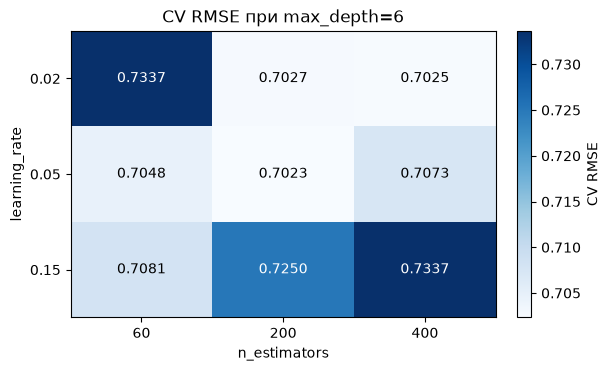

In [12]:
# Проверяем взаимодействие шага обучения и числа деревьев.
depth = grid_best["model__max_depth"]
heatmap = grid_results.loc[grid_results["max_depth"].eq(depth)].pivot(
    index="learning_rate", columns="n_estimators", values="CV RMSE")
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
image = ax.imshow(heatmap, cmap="Blues", aspect="auto")
ax.set(xticks=range(len(heatmap.columns)), xticklabels=heatmap.columns,
       yticks=range(len(heatmap.index)), yticklabels=heatmap.index,
       xlabel="n_estimators", ylabel="learning_rate",
       title=f"CV RMSE при max_depth={depth}")
for (row, col), value in np.ndenumerate(heatmap.to_numpy()):
    color = "white" if image.norm(value) > 0.62 else "black"
    ax.text(col, row, f"{value:.4f}", ha="center", va="center", color=color)
fig.colorbar(image, ax=ax, label="CV RMSE")
plt.show()

### Совместное влияние шага и числа деревьев

При глубине 6, шаге 0.02 и 60 деревьях CV RMSE равна 0.7337. Увеличение числа деревьев до 400 снижает её до 0.7025. При малом шаге модели требуется больше итераций, чтобы скорректировать прогнозы.

При шаге 0.05 минимум находится на 200 деревьях. При шаге 0.15 увеличение числа деревьев до 400 ухудшает CV RMSE до 0.7337. Одинаковое число деревьев может давать разное качество в зависимости от learning_rate, поэтому параметры подбираем совместно.

## 5. Устойчивость на фолдах и итоговый тест

Победителей фиксируем по минимальной средней CV RMSE. Затем обучаем исходную модель и две выбранные конфигурации на всём train и вычисляем RMSE на отложенной выборке. Фолды показывают, насколько результат зависит от состава валидационной части. При равном среднем меньший разброс означает более ровное качество на этих пяти фолдах.

In [13]:
# Сравниваем фолды и фиксируем победителя по CV до оценки test.
fold_scores = {"Исходная модель": -baseline_cv["test_score"]}
models = {"Исходная модель": baseline}
for name, search in searches.items():
    fold_scores[name] = np.array([
        -search.cv_results_[f"split{k}_test_score"][search.best_index_]
        for k in range(N_FOLDS)
    ])
    models[name] = clone(pipeline).set_params(**search.best_params_)

selected = min(searches, key=lambda name: fold_scores[name].mean())
print("Лучший результат среди двух поисков по CV:", selected)

fold_table = pd.DataFrame(fold_scores, index=range(1, N_FOLDS + 1))
fold_table.index.name = "Фолд"
display(fold_table.round(4))

Лучший результат среди двух поисков по CV: Random Search


,Исходная модель,Grid Search,Random Search
Фолд,,,
1,0.6785,0.6786,0.6779
2,0.7100,0.7156,0.7107
3,0.7110,0.7013,0.7028
4,0.6888,0.6938,0.6919
5,0.7272,0.7224,0.7228


Теперь обучаем три зафиксированные конфигурации на всём train. В итоговой таблице положительное снижение RMSE означает улучшение относительно исходного бустинга.

In [14]:
# Обучаем модели и получаем финальные Test RMSE.
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
test_rmse = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_rmse[name] = root_mean_squared_error(y_test, model.predict(X_test))

summary = pd.DataFrame({
    "CV RMSE": fold_table.mean(),
    "CV std": fold_table.std(ddof=0),
    "Test RMSE": test_rmse,
})
summary["Снижение CV RMSE"] = summary.loc["Исходная модель", "CV RMSE"] - summary["CV RMSE"]
summary["Снижение Test RMSE"] = summary.loc["Исходная модель", "Test RMSE"] - summary["Test RMSE"]
display(summary.round(4))

,CV RMSE,CV std,Test RMSE,Снижение CV RMSE,Снижение Test RMSE
Исходная модель,0.7031,0.0173,0.6835,0.0000,0.0000
Grid Search,0.7023,0.0156,0.6697,0.0008,0.0138
Random Search,0.7012,0.0154,0.6722,0.0019,0.0113


## 6. Выводы

Случайный поиск особенно удобен при большом числе параметров и ограниченном времени. Он может проверить больше разных значений важных параметров, тогда как сетка тратит часть попыток на повторение тех же значений в разных сочетаниях. Небольшая сетка удобна для анализа, потому что даёт сопоставимые срезы при фиксированных остальных параметрах.

Равное число обучений обеспечивает сопоставимый бюджет. Время зависит и от самих конфигураций, поскольку глубокие деревья и большое число итераций требуют больше вычислений. Разброс CV показывает устойчивость на данном разбиении. Различия между CV и test могут возникать из-за состава выборок, обучения на всём train вместо четырёх фолдов и выбора минимума среди нескольких шумных CV-оценок.

В этом прогоне Grid Search занял 54 с и снизил CV RMSE с 0.7031 до 0.7023. Random Search занял 67 с и снизил её до 0.7012. По CV выбираем Random Search. Прирост около 0.002 меньше разброса по фолдам, поэтому преимущество по среднему небольшое. Разброс уменьшился с 0.0173 у исходной модели до 0.0156 у Grid Search и 0.0154 у Random Search. На отдельных фолдах порядок моделей меняется.

Обе конфигурации улучшили локальную Test RMSE. У Grid Search она снизилась с 0.6835 до 0.6697, у Random Search — до 0.6722. Таким образом, оба поиска улучшили качество по CV и test, но их порядок поменялся. Test показывает результат на конкретной выборке, и небольшая разница между CV-оценками может поменять знак при смене состава данных. Модель для итогового выбора зафиксировали по CV до оценки на test.
